1. Mengimpor Library dan Dataset

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Mengambil dataset
kolom = ["BI-RADS", "Age", "Shape", "Margin", "Density", "Severity"]
mammo = pd.read_csv(
    "mammographic_masses.data",
    header=None,
    names=kolom,
    na_values="?"
)

#Memisahkan fitur dan target
#BI-RADS dikeluarkan karena tidak bersifat prediktif menurut dokumentasi UCI
X = mammo.drop(columns=["BI-RADS", "Severity"])
y = mammo["Severity"].squeeze()

#Menggabungkan fitur dan target
df=X.copy()
df["Severity"] = y

#Menampilkan lima baris pertama
print(df.head())

    Age  Shape  Margin  Density  Severity
0  67.0    3.0     5.0      3.0         1
1  43.0    1.0     1.0      NaN         1
2  58.0    4.0     5.0      3.0         1
3  28.0    1.0     1.0      3.0         0
4  74.0    1.0     5.0      NaN         1


2. Eksplorasi Data

In [8]:
print("Dimensi dataset:", df.shape)

#Informasi variabel
print(df.info())

#Statistik deskriptif
print(df.describe())

#Memeriksa missing values
print(df.isnull().sum())

#Memeriksa duplikasi
print("Jumlah duplikasi:", df.duplicated().sum())

#Distribusi kelas
print(df["Severity"].value_counts())

#Persentase distribusi kelas
print(df["Severity"].value_counts(normalize=True)*100)

#Menghapus observasi yang memiliki nilai kosong
df = df.dropna().reset_index(drop=True)

X = df.drop(columns="Severity")
y = df["Severity"]

print("Dimensi dataset setelah penanganan:", df.shape)
print(df.isnull().sum())

print(df["Severity"].value_counts())
print(df["Severity"].value_counts(normalize=True) * 100)

Dimensi dataset: (961, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 961 entries, 0 to 960
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Age       956 non-null    float64
 1   Shape     930 non-null    float64
 2   Margin    913 non-null    float64
 3   Density   885 non-null    float64
 4   Severity  961 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 37.7 KB
None
              Age       Shape      Margin     Density    Severity
count  956.000000  930.000000  913.000000  885.000000  961.000000
mean    55.487448    2.721505    2.796276    2.910734    0.463059
std     14.480131    1.242792    1.566546    0.380444    0.498893
min     18.000000    1.000000    1.000000    1.000000    0.000000
25%     45.000000    2.000000    1.000000    3.000000    0.000000
50%     57.000000    3.000000    3.000000    3.000000    0.000000
75%     66.000000    4.000000    4.000000    3.000000    1.000000
max     96.00

3. Visualisasi Distribusi Kelas

a. Visualisasi Kelas Severity

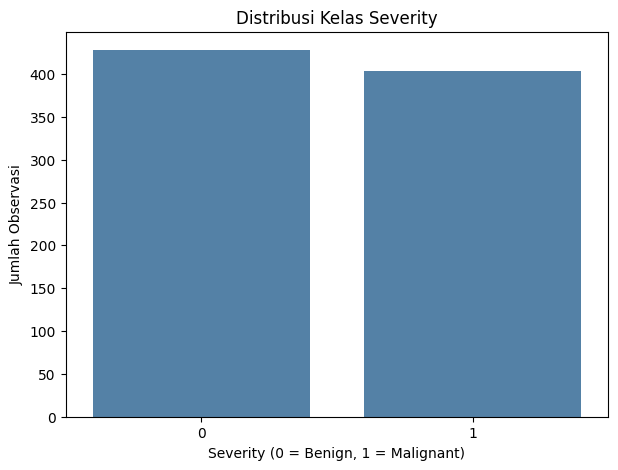

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Severity",
    order=[0, 1],
    color="steelblue"
)

plt.title("Distribusi Kelas Severity")
plt.xlabel("Severity (0 = Benign, 1 = Malignant)")
plt.ylabel("Jumlah Observasi")

plt.show()

b. Visualisasi Heatmap Korelasi

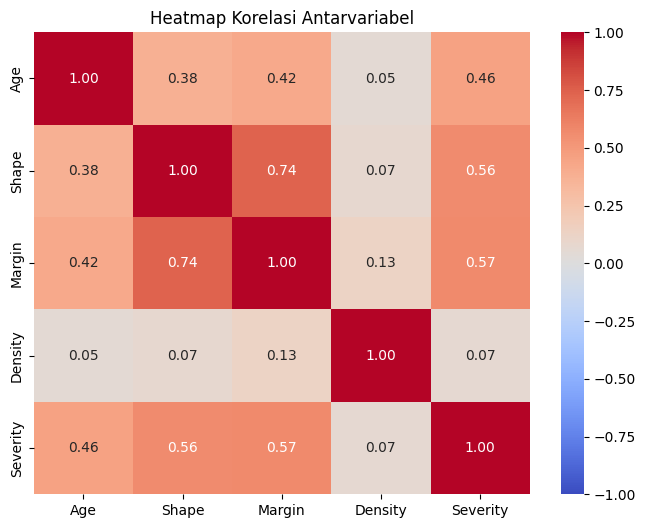

In [10]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Heatmap Korelasi Antarvariabel")
plt.show()

c. Visualisasi Histogram

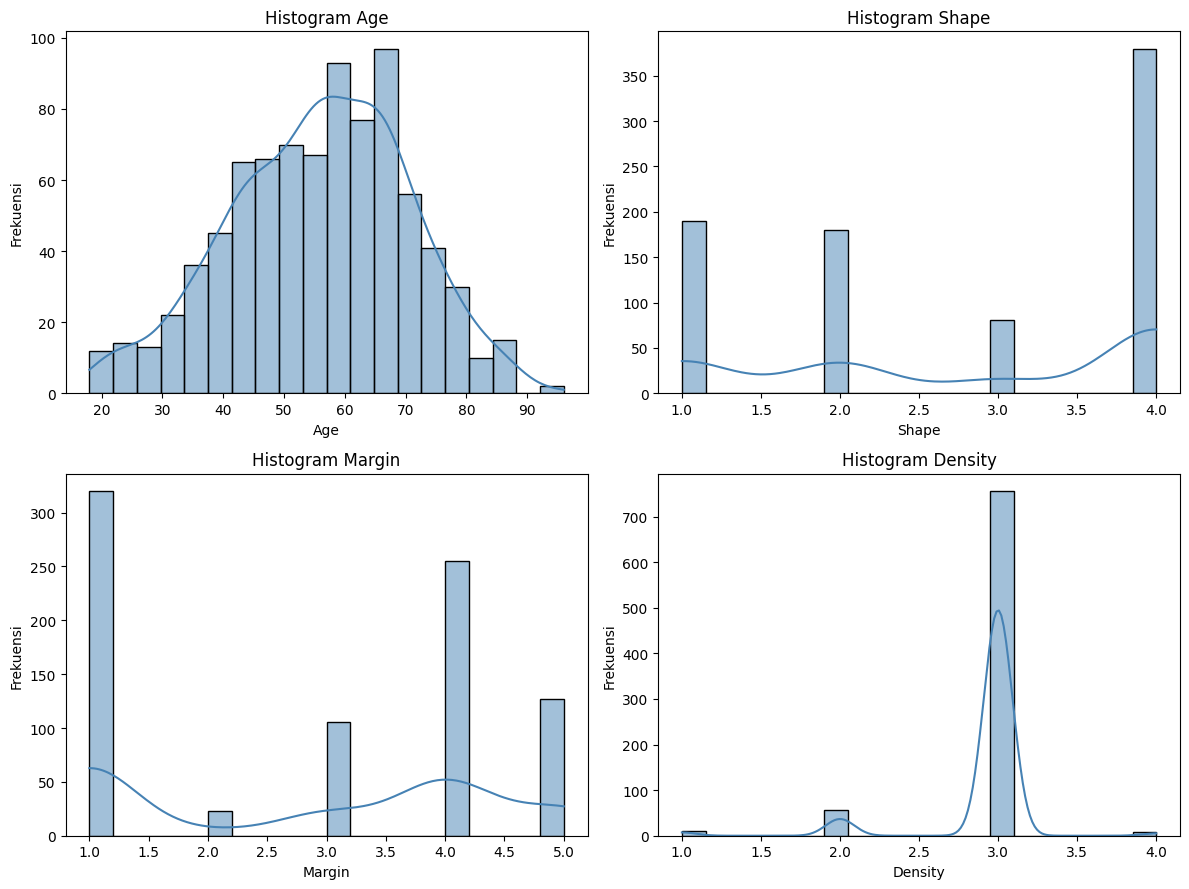

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, kolom_x in zip(axes.flat, X.columns):

    sns.histplot(
        data=df,
        x=kolom_x,
        bins=20,
        kde=True,
        color="steelblue",
        ax=ax
    )

    ax.set_title("Histogram " + kolom_x)
    ax.set_xlabel(kolom_x)
    ax.set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()

d. Visualisasi Boxplot

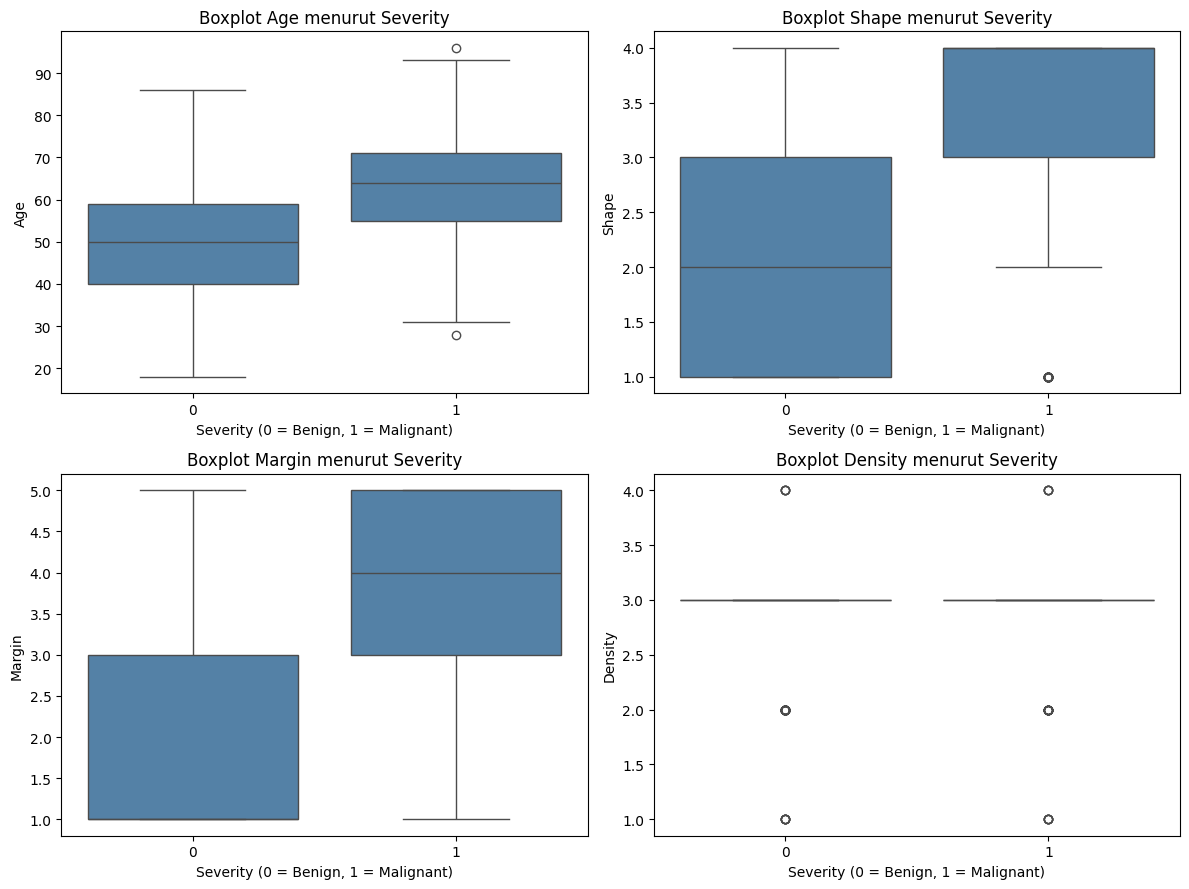

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, kolom_x in zip(axes.flat, X.columns):

    sns.boxplot(
        data=df,
        x="Severity",
        y=kolom_x,
        order=[0, 1],
        color="steelblue",
        ax=ax
    )

    ax.set_title("Boxplot " + kolom_x + " menurut Severity")
    ax.set_xlabel("Severity (0 = Benign, 1 = Malignant)")
    ax.set_ylabel(kolom_x)

plt.tight_layout()
plt.show()

4. Membagi Data Latih dan Data Uji

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Jumlah data latih:", X_train.shape[0])
print("Jumlah data uji:", X_test.shape[0])

print("\nDistribusi kelas data latih:")
print(y_train.value_counts())

print("\nDistribusi kelas data uji:")
print(y_test.value_counts())

Jumlah data latih: 664
Jumlah data uji: 167

Distribusi kelas data latih:
Severity
0    342
1    322
Name: count, dtype: int64

Distribusi kelas data uji:
Severity
0    86
1    81
Name: count, dtype: int64


5. Pemeriksaan Distribusi Kelas pada Data Training dan Data Testing

In [14]:
#Distribusi kelas pada data training
print("Distribusi Kelas Training:")
print(y_train.value_counts())

print("\nPersentase Kelas Training:")
print(y_train.value_counts(normalize=True)*100)

#Distribusi kelas pada data testing
print("\nDistribusi Kelas Testing:")
print(y_test.value_counts())

print("\nPersentase Kelas Testing:")
print(y_test.value_counts(normalize=True)*100)

Distribusi Kelas Training:
Severity
0    342
1    322
Name: count, dtype: int64

Persentase Kelas Training:
Severity
0    51.506024
1    48.493976
Name: proportion, dtype: float64

Distribusi Kelas Testing:
Severity
0    86
1    81
Name: count, dtype: int64

Persentase Kelas Testing:
Severity
0    51.497006
1    48.502994
Name: proportion, dtype: float64


6. Penerapan SMOTE pada Data Training

In [15]:
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

#Standardisasi berdasarkan data training
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

#Menerapkan SMOTE
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Sebelum SMOTE:")
print(y_train.value_counts())

print("\nSetelah SMOTE:")
print(y_train_smote.value_counts())

print("\nPersentase Sebelum SMOTE:")
print(y_train.value_counts(normalize=True)*100)

print("\nPersentase Setelah SMOTE:")
print(y_train_smote.value_counts(normalize=True)*100)

Sebelum SMOTE:
Severity
0    342
1    322
Name: count, dtype: int64

Setelah SMOTE:
Severity
0    342
1    342
Name: count, dtype: int64

Persentase Sebelum SMOTE:
Severity
0    51.506024
1    48.493976
Name: proportion, dtype: float64

Persentase Setelah SMOTE:
Severity
0    50.0
1    50.0
Name: proportion, dtype: float64


Visualisasi Distribusi Kelas Sebelum Sesudah SMOTE

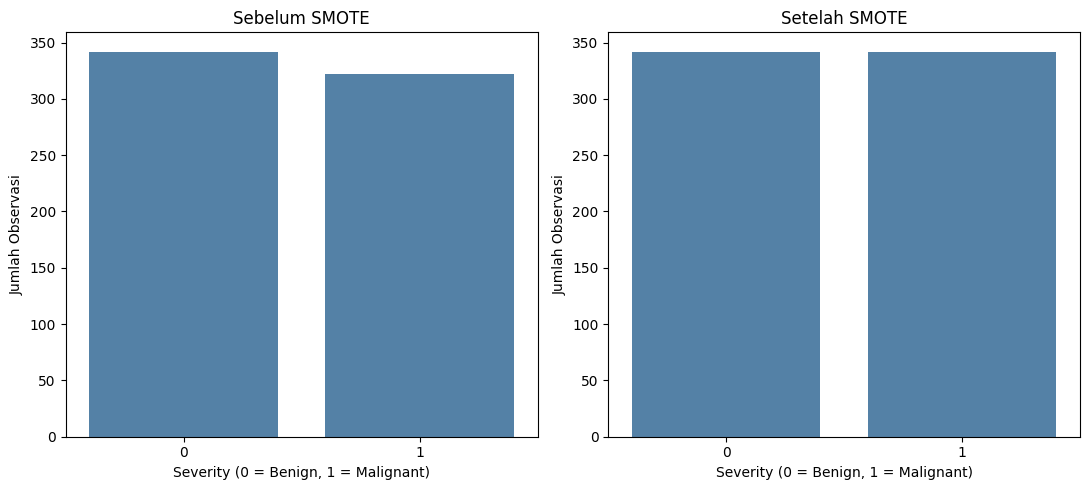

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

sns.countplot(
    x=y_train,
    order=[0, 1],
    color="steelblue",
    ax=axes[0]
)
axes[0].set_title("Sebelum SMOTE")
axes[0].set_xlabel("Severity (0 = Benign, 1 = Malignant)")
axes[0].set_ylabel("Jumlah Observasi")

sns.countplot(
    x=y_train_smote,
    order=[0, 1],
    color="steelblue",
    ax=axes[1]
)
axes[1].set_title("Setelah SMOTE")
axes[1].set_xlabel("Severity (0 = Benign, 1 = Malignant)")
axes[1].set_ylabel("Jumlah Observasi")

plt.tight_layout()
plt.show()

7. Membangun Model Klasifikasi

In [17]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

models = {
    "DT - Asli": Pipeline([
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "DT - SMOTE": Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "RF - Asli": Pipeline([
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]),

    "RF - SMOTE": Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ])
}

#Melatih keempat model
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} berhasil dilatih")

DT - Asli berhasil dilatih
DT - SMOTE berhasil dilatih
RF - Asli berhasil dilatih
RF - SMOTE berhasil dilatih


8. Melakukan Prediksi pada Data Training dan Data Testing

In [18]:
predictions = {}

for name, model in models.items():

    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    predictions[name] = {
        "Training": y_pred_train,
        "Testing": y_pred_test
    }

    print(f"\n{name}")
    print("Prediksi Training:", y_pred_train[:5])
    print("Prediksi Testing :", y_pred_test[:5])


DT - Asli
Prediksi Training: [0 0 0 1 1]
Prediksi Testing : [0 1 0 1 0]

DT - SMOTE
Prediksi Training: [0 0 0 1 1]
Prediksi Testing : [0 1 0 1 0]

RF - Asli
Prediksi Training: [1 0 0 1 1]
Prediksi Testing : [0 1 0 1 0]

RF - SMOTE
Prediksi Training: [1 0 0 1 1]
Prediksi Testing : [0 1 0 1 0]


9. Mengevaluasi kinerja model klasifikasi

In [19]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

evaluation_results = []

for name in models.keys():

    for dataset, y_actual in [
        ("Training", y_train),
        ("Testing", y_test)
    ]:

        y_pred = predictions[name][dataset]

        evaluation_results.append({
            "Model": name,
            "Dataset": dataset,
            "Accuracy": accuracy_score(y_actual, y_pred),
            "Precision": precision_score(
                y_actual, y_pred,
                pos_label=1,
                zero_division=0
            ),
            "Recall": recall_score(
                y_actual, y_pred,
                pos_label=1,
                zero_division=0
            ),
            "F1-Score": f1_score(
                y_actual, y_pred,
                pos_label=1,
                zero_division=0
            )
        })

evaluation_df = pd.DataFrame(evaluation_results)

print(evaluation_df.round(4).to_string(index=False))

     Model  Dataset  Accuracy  Precision  Recall  F1-Score
 DT - Asli Training    0.9142     0.9102  0.9130    0.9116
 DT - Asli  Testing    0.7485     0.7468  0.7284    0.7375
DT - SMOTE Training    0.9142     0.9102  0.9130    0.9116
DT - SMOTE  Testing    0.7305     0.7195  0.7284    0.7239
 RF - Asli Training    0.9142     0.8863  0.9441    0.9143
 RF - Asli  Testing    0.7725     0.7529  0.7901    0.7711
RF - SMOTE Training    0.9142     0.8863  0.9441    0.9143
RF - SMOTE  Testing    0.7665     0.7386  0.8025    0.7692


10. Memvisualisasikan Confusion Matrix

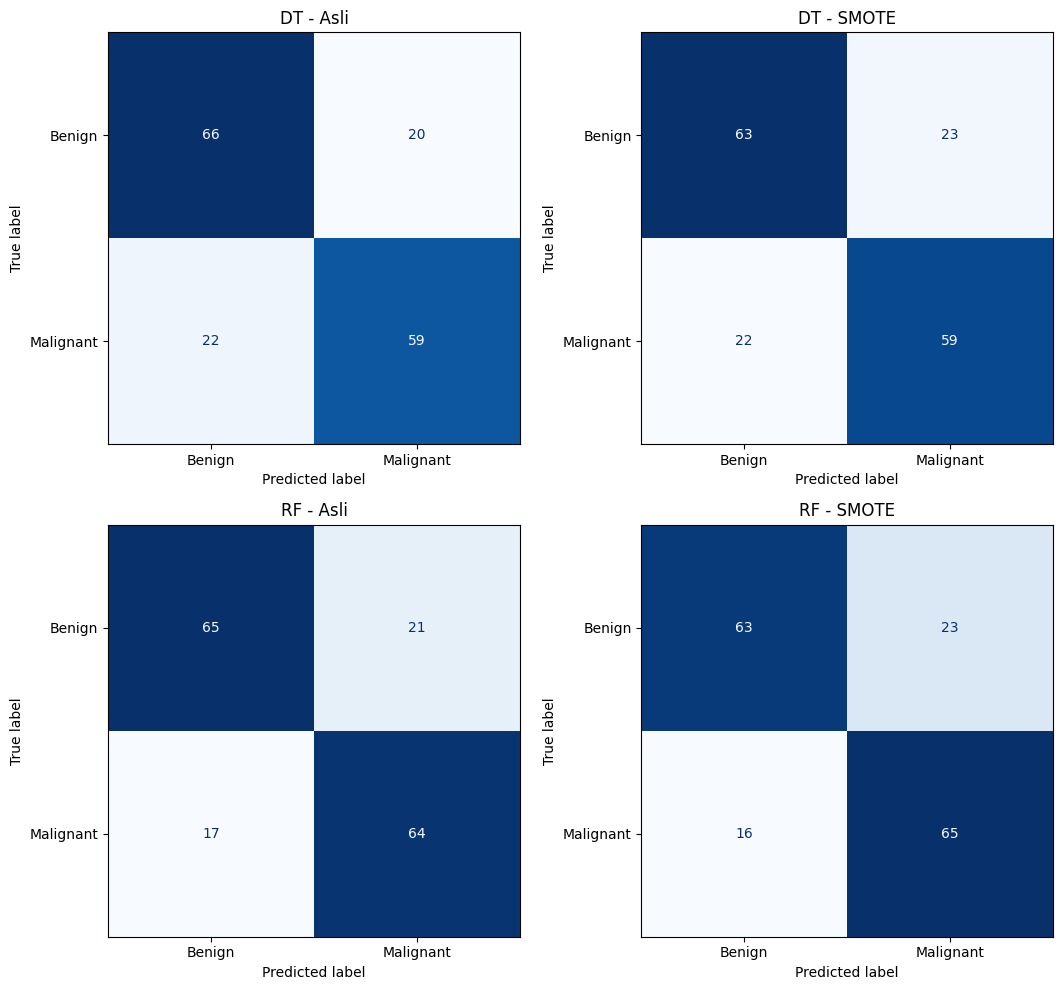

In [20]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

fig, axes = plt.subplots(2, 2, figsize=(11, 10))

for ax, (name, model) in zip(axes.flat, models.items()):

    y_pred = predictions[name]["Testing"]

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

Jumlah TN, FP, FN, TP

In [21]:
for name in models.keys():

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions[name]["Testing"],
        labels=[0, 1]
    ).ravel()

    print(f"{name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

DT - Asli: TN=66, FP=20, FN=22, TP=59
DT - SMOTE: TN=63, FP=23, FN=22, TP=59
RF - Asli: TN=65, FP=21, FN=17, TP=64
RF - SMOTE: TN=63, FP=23, FN=16, TP=65


11. Membandingkan kinerja keempat model

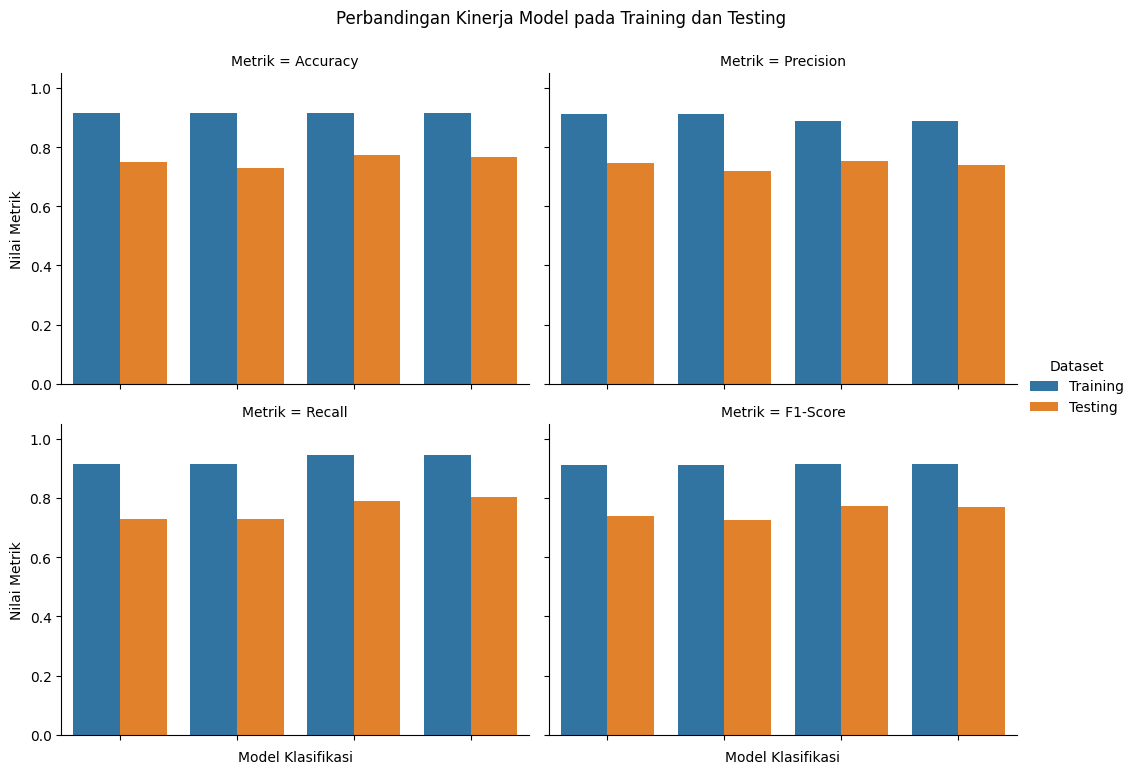

Peringkat Model Berdasarkan F1-Score Testing
     Model Dataset  Accuracy  Precision  Recall  F1-Score
 RF - Asli Testing    0.7725     0.7529  0.7901    0.7711
RF - SMOTE Testing    0.7665     0.7386  0.8025    0.7692
 DT - Asli Testing    0.7485     0.7468  0.7284    0.7375
DT - SMOTE Testing    0.7305     0.7195  0.7284    0.7239


In [22]:
import seaborn as sns

#Mengubah data menjadi format long
evaluation_long = evaluation_df.melt(
    id_vars=["Model", "Dataset"],
    value_vars=[
        "Accuracy", "Precision",
        "Recall", "F1-Score"
    ],
    var_name="Metrik",
    value_name="Nilai"
)

#Visualisasi seluruh metrik
g = sns.catplot(
    data=evaluation_long,
    x="Model",
    y="Nilai",
    hue="Dataset",
    col="Metrik",
    kind="bar",
    col_wrap=2,
    height=4,
    aspect=1.3,
    sharey=True
)

g.set(ylim=(0, 1.05))
g.set_xticklabels(rotation=45)
g.set_axis_labels("Model Klasifikasi", "Nilai Metrik")
g.fig.subplots_adjust(top=0.90)
g.fig.suptitle(
    "Perbandingan Kinerja Model pada Training dan Testing"
)

plt.show()

#Mengurutkan hasil evaluasi data testing
testing_results = evaluation_df[
    evaluation_df["Dataset"] == "Testing"
].copy()

testing_results = testing_results.sort_values(
    by="F1-Score",
    ascending=False
)

print("Peringkat Model Berdasarkan F1-Score Testing")
print(testing_results.round(4).to_string(index=False))

12. Membandingkan Prediksi Random Forest

In [23]:
import numpy as np

pred_asli = models["RF - Asli"].predict(X_test)
pred_smote = models["RF - SMOTE"].predict(X_test)

print("Jumlah prediksi berbeda:",
      np.sum(pred_asli != pred_smote))

Jumlah prediksi berbeda: 3


13. Probabilitas Prediksi Random Frest

In [24]:
import pandas as pd
import numpy as np

prob_asli = models["RF - Asli"].predict_proba(X_test)[:, 1]
prob_smote = models["RF - SMOTE"].predict_proba(X_test)[:, 1]

perbandingan = pd.DataFrame({
    "Aktual": y_test.to_numpy(),
    "Prediksi_Asli": models["RF - Asli"].predict(X_test),
    "Prediksi_SMOTE": models["RF - SMOTE"].predict(X_test),
    "Prob_M_Asli": prob_asli,
    "Prob_M_SMOTE": prob_smote
})

print(perbandingan.head(10))

   Aktual  Prediksi_Asli  Prediksi_SMOTE  Prob_M_Asli  Prob_M_SMOTE
0       0              0               0     0.037500      0.005000
1       1              1               1     0.822000      0.836643
2       0              0               0     0.035000      0.020000
3       1              1               1     1.000000      1.000000
4       0              0               0     0.000000      0.000000
5       0              0               0     0.000000      0.000000
6       0              0               0     0.000000      0.000000
7       1              1               1     0.840000      0.850000
8       0              1               1     0.946000      0.967667
9       0              0               0     0.237222      0.237698


14. Scatter Plot Probabilitas

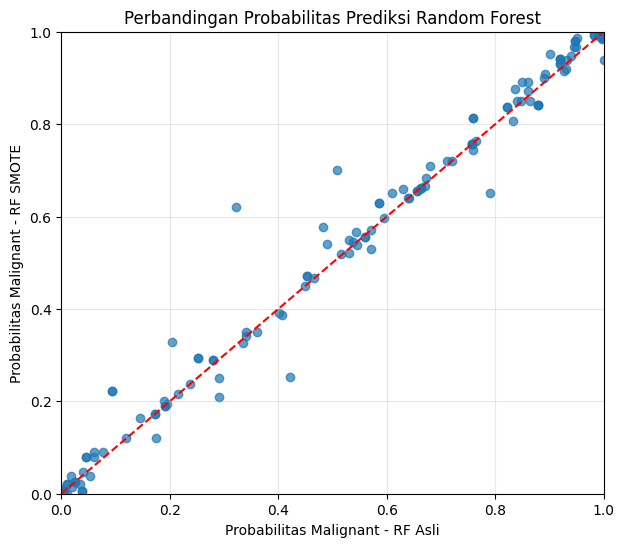

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(
    prob_asli,
    prob_smote,
    alpha=0.7
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="red"
)

plt.xlabel("Probabilitas Malignant - RF Asli")
plt.ylabel("Probabilitas Malignant - RF SMOTE")
plt.title("Perbandingan Probabilitas Prediksi Random Forest")

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)

plt.show()

15. Hyperparameter Tuning

In [28]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score
import pandas as pd

# Skor F1 dengan kelas positif = 1 (Malignant)
f1_pos = make_scorer(f1_score, pos_label=1, zero_division=0)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Kandidat hyperparameter untuk DT dan RF
param_grids = {
    "DT": {
        "model__criterion": ["gini", "entropy"],
        "model__max_depth": [3, 5, 7, None],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4]
    },
    "RF": {
        "model__criterion": ["gini", "entropy"],
        "model__max_depth": [3, 5, 7, None],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2"]
    }
}

best_models = {}
tuning_results = []

for name, model in models.items():
    # Menentukan grid parameter berdasarkan inisial model (DT atau RF)
    prefix = "DT" if name.startswith("DT") else "RF"

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grids[prefix],
        scoring=f1_pos,
        cv=cv,
        n_jobs=-1
    )

    grid.fit(X_train, y_train)
    best_models[name] = grid.best_estimator_

    print(f"\n{name}")
    print("Hyperparameter terbaik:", grid.best_params_)
    print("F1-Score CV terbaik   :", round(grid.best_score_, 4))

    tuning_results.append({
        "Model": name,
        "Criterion": grid.best_params_["model__criterion"],
        "F1 CV": grid.best_score_
    })

tuning_df = pd.DataFrame(tuning_results)
print("\nRingkasan Hyperparameter Terbaik")
print(tuning_df.round(4).to_string(index=False))


DT - Asli
Hyperparameter terbaik: {'model__criterion': 'entropy', 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
F1-Score CV terbaik   : 0.8059

DT - SMOTE
Hyperparameter terbaik: {'model__criterion': 'gini', 'model__max_depth': 5, 'model__min_samples_leaf': 4, 'model__min_samples_split': 2}
F1-Score CV terbaik   : 0.815

RF - Asli
Hyperparameter terbaik: {'model__criterion': 'gini', 'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 4}
F1-Score CV terbaik   : 0.8245

RF - SMOTE
Hyperparameter terbaik: {'model__criterion': 'gini', 'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 4}
F1-Score CV terbaik   : 0.8237

Ringkasan Hyperparameter Terbaik
     Model Criterion  F1 CV
 DT - Asli   entropy 0.8059
DT - SMOTE      gini 0.8150
 RF - Asli      gini 0.8245
RF - SMOTE      gini 0.8237


16. Evaluasi Model Setelah Tunning

In [29]:
tuned_results = []

for name, model in best_models.items():

    for dataset, X_data, y_actual in [
        ("Training", X_train, y_train),
        ("Testing", X_test, y_test)
    ]:

        y_pred = model.predict(X_data)

        tuned_results.append({
            "Model": name + " (Tuned)",
            "Dataset": dataset,
            "Accuracy": accuracy_score(y_actual, y_pred),
            "Precision": precision_score(
                y_actual, y_pred,
                pos_label=1,
                zero_division=0
            ),
            "Recall": recall_score(
                y_actual, y_pred,
                pos_label=1,
                zero_division=0
            ),
            "F1-Score": f1_score(
                y_actual, y_pred,
                pos_label=1,
                zero_division=0
            )
        })

tuned_df = pd.DataFrame(tuned_results)

print("Evaluasi Model Setelah Tuning")
print(tuned_df.round(4).to_string(index=False))

#Perbandingan sebelum dan sesudah tuning (data testing)
semua_df = pd.concat([evaluation_df, tuned_df], ignore_index=True)

semua_testing = semua_df[
    semua_df["Dataset"] == "Testing"
].sort_values(by="F1-Score", ascending=False)

print("\nPeringkat Seluruh Model (Testing) berdasarkan F1-Score")
print(semua_testing.round(4).to_string(index=False))

Evaluasi Model Setelah Tuning
             Model  Dataset  Accuracy  Precision  Recall  F1-Score
 DT - Asli (Tuned) Training    0.8057     0.7468  0.9068    0.8191
 DT - Asli (Tuned)  Testing    0.7784     0.7292  0.8642    0.7910
DT - SMOTE (Tuned) Training    0.8419     0.8039  0.8913    0.8454
DT - SMOTE (Tuned)  Testing    0.7485     0.7407  0.7407    0.7407
 RF - Asli (Tuned) Training    0.8328     0.7955  0.8820    0.8365
 RF - Asli (Tuned)  Testing    0.7784     0.7750  0.7654    0.7702
RF - SMOTE (Tuned) Training    0.8343     0.7994  0.8789    0.8373
RF - SMOTE (Tuned)  Testing    0.7844     0.7778  0.7778    0.7778

Peringkat Seluruh Model (Testing) berdasarkan F1-Score
             Model Dataset  Accuracy  Precision  Recall  F1-Score
 DT - Asli (Tuned) Testing    0.7784     0.7292  0.8642    0.7910
RF - SMOTE (Tuned) Testing    0.7844     0.7778  0.7778    0.7778
         RF - Asli Testing    0.7725     0.7529  0.7901    0.7711
 RF - Asli (Tuned) Testing    0.7784     0.7750